In [1]:
import pandas as pd
import numpy as np
import networkx as nx
from torch_geometric.datasets import TUDataset
from diversity_curves.utils import graph_processing_torch
from diversity_curves.stats import two_sample_test_matrix

Read in the dataset and the precomputed diversity curves for the ENZYMES and PROTEINS datasets.

In [2]:
dataset_names = ["ENZYMES", "PROTEINS"]
all_y=[]
for c in dataset_names:
    root = "./../data/TUDataset"
    pyg_dataset = TUDataset(root=root, name=c)

    van_graph_list = graph_processing_torch(pyg_dataset)
    lables = [data.y.item() for data in pyg_dataset]
    all_y.extend(lables)

In [3]:
dataset_label =[]
df_all = pd.DataFrame()
for d in dataset_names:
    pyg_dataset = TUDataset(root=root, name=d)

    van_graph_list = graph_processing_torch(pyg_dataset)
    lables = [d+"_"+str(data.y.item()) for data in pyg_dataset]
    df = pd.read_csv(f"./results/{d}/mag_funs_shortest_path_distance.csv", index_col=0)
    dataset_label.extend([d]*len(df))
    df["dataset"] = d
    df["class"] = lables
    df_all = pd.concat([df_all, df], ignore_index=True)

Linearily interpolate the diversity curves, subset to node sizes between 1 and 35 nodes and convert the dataframe for plotting.

In [4]:
# Linear interpolation per column for NaN entries (numeric columns only)
num_cols = [str(i) for i in range(1, 91)]
df_all = df_all[num_cols+["dataset", "class"]]
df_all_copy = df_all.copy()
num_cols = df_all_copy.select_dtypes(include=[np.number]).columns
df_all_copy[num_cols] = df_all_copy[num_cols].interpolate(method="linear", axis=0, limit_direction="both")

In [5]:
df_long = (
    df_all_copy
    .reset_index()
    .rename(columns={"index": "graph_index"})
    .melt(
        id_vars=["graph_index", "dataset", "class"],
        value_vars=num_cols,
        var_name="n_nodes",
        value_name="value"
    )
)

df_long["n_nodes"] = df_long["n_nodes"].astype(int)
df_long = df_long[df_long.n_nodes < 35]

Plot the diversity curves as in Figure S.8 of the manuscript.

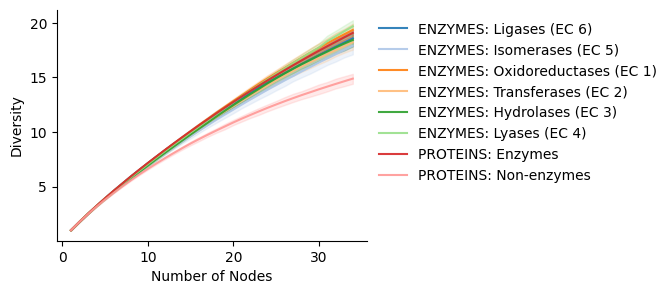

In [6]:
import seaborn as sns
import matplotlib.pyplot as plt
df_long2 = df_long[df_long.n_nodes < 35]
dict_rename = {"PROTEINS_0": "PROTEINS: Enzymes", "PROTEINS_1": "PROTEINS: Non-enzymes"}

names=["Oxidoreductases (EC 1)", "Transferases (EC 2)", "Hydrolases (EC 3)", "Lyases (EC 4)", "Isomerases (EC 5)", "Ligases (EC 6)"]

for r in range(6):
    dict_rename[f"ENZYMES_{r}"]= "ENZYMES: " + names[r]
df_long2["class"] = df_long2["class"].map(dict_rename)
plt.figure(figsize=(4,3))
sns.lineplot(data=df_long2[(df_long2.dataset=="ENZYMES") | (df_long2.dataset=="PROTEINS")], x="n_nodes", y="value", hue="class", palette="tab20", alpha=0.9)
sns.despine()
plt.legend(bbox_to_anchor=(1, 1), frameon=False)
sns.despine()
plt.xlabel("Number of Nodes")
plt.ylabel("Diversity")
plt.grid(False)
plt.savefig("./results/tu_data_curves_classes.pdf", bbox_inches='tight')
plt.show()

Run the two sample permutation test for equality in means across each ENZYMES or PROTEINS class. Rename the classes to match the correct annotations and save the test results as the heatmap of p-values from Figure 6 in the manuscript.

In [7]:
test_results_df, test_results_stats_df = two_sample_test_matrix(df_all_copy, class_col="class", drop_cols=("class", "dataset"), n_permutations=1000, seed=42,)

In [8]:
new_index = test_results_df.index.map(dict_rename)
test_results_df.index = new_index
test_results_df.columns = new_index

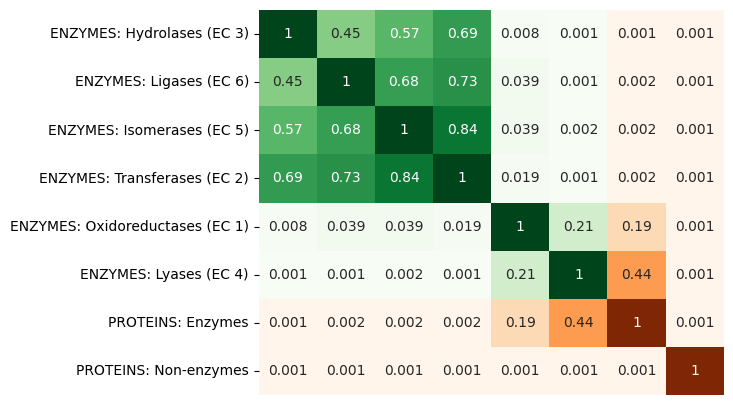

In [9]:
order = ["ENZYMES: Hydrolases (EC 3)",
        "ENZYMES: Ligases (EC 6)",
         "ENZYMES: Isomerases (EC 5)",
         "ENZYMES: Transferases (EC 2)",
         "ENZYMES: Oxidoreductases (EC 1)",
         "ENZYMES: Lyases (EC 4)",
         "PROTEINS: Enzymes", 
         "PROTEINS: Non-enzymes"]
test_results_df_sub_plot = test_results_df.loc[order,order]
plt.figure(figsize=(6,5))

mask_main = np.zeros_like(test_results_df_sub_plot, dtype=bool)
mask_main[-2:, :] = True
mask_main[:, -2:] = True  

mask_last = ~mask_main  
sns.heatmap(test_results_df_sub_plot, mask=mask_main, cmap="Greens", cbar=False, annot=True)

sns.heatmap(test_results_df_sub_plot, mask=mask_last, cmap="Oranges", cbar=False, annot=True)

plt.xticks([])
n_rows = test_results_df_sub_plot.shape[0]
x_pos = -4

plt.savefig("./results/tu_data_perm_test_classes.pdf", bbox_inches='tight')
plt.show()